# A gated bilayer graphene quantum dot with the implicit method

The [graphene multilayers tutorial](/contents/demos/nm4qm-17-10-2026/notebooks/index.html?path=graphene_multilayers.ipynb) had 4 or 6 bands.
Now we take a bilayer graphene sheet with 32,400 orbitals, where a gate creates a **quantum dot**.
**How do the dot levels move when we change the gate voltage?**

![Gated bilayer graphene quantum dot. Side view: the bilayer lies between a back gate and a top gate, which set the displacement field D and put the layers at potential energies +D and -D. A dot gate in a gap of the top gate creates a Gaussian potential well of depth V_gate and width sigma, which binds the dot states. Top view: the sheet is periodic; the rhombus-shaped supercell spanned by 90 a_1 and 90 a_2 contains one dot in its center, and its periodic copies contain copies of the dot.](attachment:dot.png)

The exact answer needs one sparse diagonalization per gate voltage; perturbation theory gives all voltages at once.
All eigenvectors of a $32{,}400 \times 32{,}400$ matrix would take 8 GB, so we use Pymablock's **implicit method**:
we pass only the eigenvectors of the states we keep, and Pymablock solves sparse linear systems for the rest.
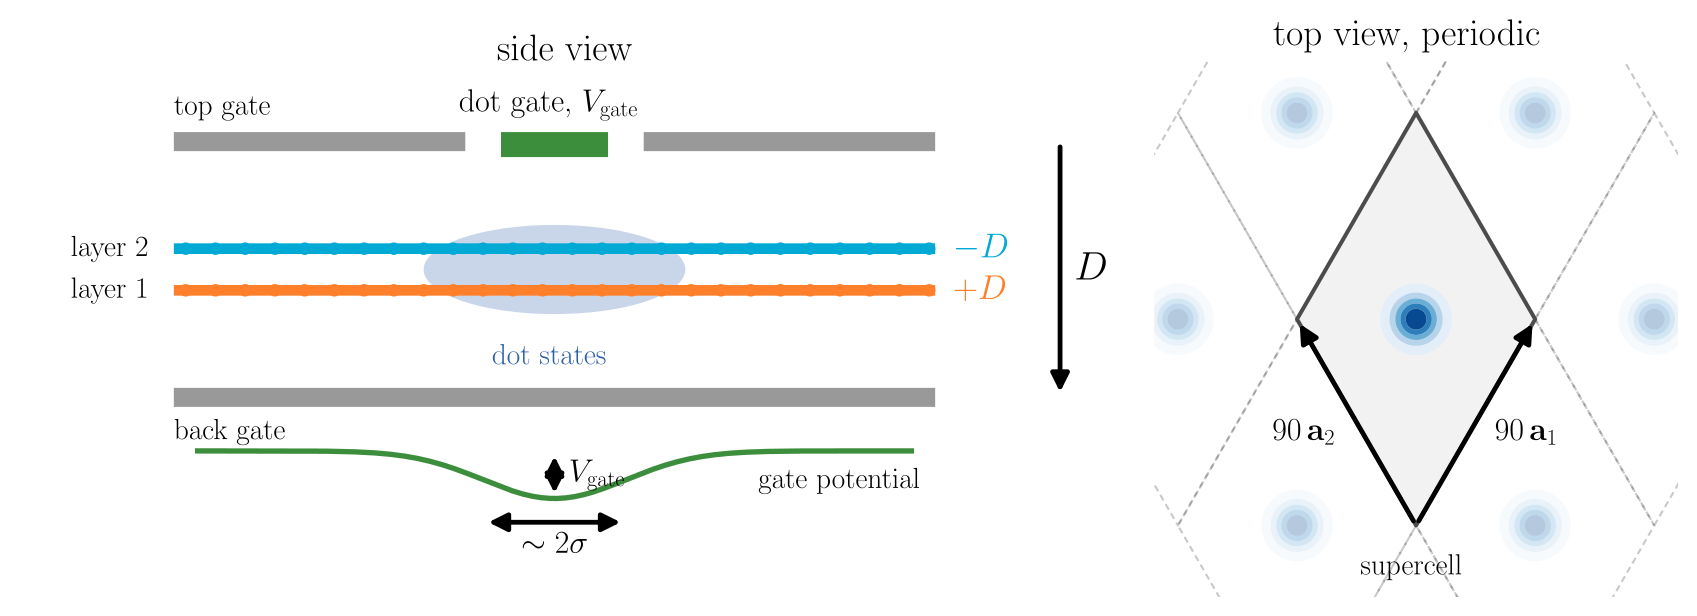

In [ ]:
# Install Pymablock in the browser; numpy, scipy, sympy, and matplotlib come with Pyodide.
# This site serves a build of Pymablock's main branch, which solves sparse systems with
# SciPy when MUMPS is unavailable (as in the browser).
%pip install -q pymablock

In [ ]:
"""NM4QM tutorial: a gated bilayer graphene quantum dot with the implicit method."""

from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import scipy.sparse as sparse
import scipy.sparse.linalg as sla
from scipy.interpolate import griddata

from pymablock import block_diagonalize


## Building the dot

We build the tight-binding model of bilayer graphene as a sparse matrix, with hoppings $t_1$ and $t_2$ and two onsite terms:

- the displacement field, $\pm D$ on the two layers;
- the gate, a Gaussian well $-V_\mathrm{gate}\, e^{-r^2/2\sigma^2}$.

Edges host states inside the gap, so we use a periodic $90 \times 90$ supercell (22 nm wide) instead.
Lengths are in units of the lattice constant $a = 0.246\ \mathrm{nm}$.
The sublattices $A_1, B_1, A_2, B_2$ are numbered 0 to 3; each $B$ site has $A$ neighbors in cells $(i, j)$, $(i + 1, j)$, and $(i, j + 1)$, taken modulo 90.

In [ ]:
graphene_a_1 = np.array([1 / 2, np.sqrt(3) / 2])
graphene_a_2 = np.array([-1 / 2, np.sqrt(3) / 2])
bond = (graphene_a_1 + graphene_a_2) / 3

n_cells = 90
cell_i, cell_j = (index.ravel() for index in np.indices((n_cells, n_cells)))
sublattice_offsets = [0, 1, 1, 2]  # in units of `bond`; A_2 sits on top of B_1
layer_sign = np.repeat([1, 1, -1, -1], n_cells**2)

dot_center = n_cells * (graphene_a_1 + graphene_a_2) / 2
positions = (
    np.concatenate(
        [
            np.outer(cell_i, graphene_a_1)
            + np.outer(cell_j, graphene_a_2)
            + offset * bond
            for offset in sublattice_offsets
        ]
    )
    - dot_center
)


def site_index(sublattice, i, j):
    """Orbital index of the `sublattice` site in cell (i, j) of the periodic sheet."""
    return sublattice * n_cells**2 + (i % n_cells) * n_cells + j % n_cells


def gate_profile(r, sigma):
    """Shape of the gate potential, 1 in the center of the dot."""
    return np.exp(-(r**2) / (2 * sigma**2))


def dot_hamiltonian(parameters):
    """Sparse Hamiltonian of the periodic bilayer sheet."""
    bonds = [  # (sublattice of row, sublattice of column, cell shift, hopping)
        (A, B, shift, parameters["t_1"])
        for A, B in ((0, 1), (2, 3))
        for shift in ((0, 0), (1, 0), (0, 1))
    ] + [(2, 1, (0, 0), parameters["t_2"])]
    rows = np.concatenate(
        [site_index(A, cell_i + di, cell_j + dj) for A, _, (di, dj), _ in bonds]
    )
    columns = np.concatenate([site_index(B, cell_i, cell_j) for _, B, _, _ in bonds])
    hoppings = np.repeat([t for *_, t in bonds], n_cells**2)
    hopping_matrix = sparse.coo_array(
        (hoppings, (rows, columns)), shape=(len(positions),) * 2
    )

    gate = gate_profile(np.linalg.norm(positions, axis=1), parameters["sigma"])
    onsite = layer_sign * parameters["D"] - parameters["V_gate"] * gate
    return (hopping_matrix + hopping_matrix.T + sparse.diags_array(onsite)).tocsc()

A strong displacement field gives a wide gap, and the well has $\sigma = 8a = 2\ \mathrm{nm}$, much smaller than real dots, so that the matrix stays small.
Energies are in eV.

In [ ]:
dot_parameters = dict(t_1=3.0, t_2=0.4, D=0.2, V_gate=0.2, sigma=8.0)

start = perf_counter()
H_dot = dot_hamiltonian(dot_parameters)
print(f"{H_dot.shape[0]} orbitals, {H_dot.nnz} nonzero matrix elements")
print(f"built in {perf_counter() - start:.2f} s")

The matrix couples the four sublattices, and its diagonal holds the displacement field and the gate well:

In [ ]:
fig, (ax_matrix, ax_1, ax_2) = plt.subplots(1, 3, figsize=(10, 3.4), layout="constrained")
ax_matrix.spy(H_dot, markersize=0.02, color="black")
block = n_cells**2
names = ["$A_1$", "$B_1$", "$A_2$", "$B_2$"]
ax_matrix.set_xticks(block * (np.arange(4) + 0.5), names)
ax_matrix.set_yticks(block * (np.arange(4) + 0.5), names)
ax_matrix.tick_params(top=False, labeltop=False, bottom=True, labelbottom=True)
for edge in block * np.arange(1, 4):
    ax_matrix.axhline(edge, color="0.8", lw=0.8)
    ax_matrix.axvline(edge, color="0.8", lw=0.8)
ax_matrix.set_title(f"$H$, {H_dot.shape[0]} orbitals", fontsize=11)

# Onsite energies on a square window of the periodic sheet, mapped back into the supercell.
grid_x, grid_y = np.meshgrid(*2 * [np.linspace(-n_cells / 2, n_cells / 2, 300)])
lattice_vectors = np.array([graphene_a_1, graphene_a_2]).T
window = np.stack([grid_x.ravel(), grid_y.ravel()], axis=1) + dot_center
cell_coordinates = np.linalg.solve(lattice_vectors, window.T)
grid = (lattice_vectors @ (cell_coordinates % n_cells)).T
onsite = H_dot.diagonal()
for ax, layer in ((ax_1, 0), (ax_2, 1)):
    sites = slice(2 * layer * block, 2 * (layer + 1) * block)
    image = ax.imshow(
        griddata(
            positions[sites] + dot_center, onsite[sites], grid, method="nearest"
        ).reshape(grid_x.shape),
        extent=(-n_cells / 2, n_cells / 2, -n_cells / 2, n_cells / 2),
        origin="lower",
        cmap="RdBu_r",
        vmin=-0.4,
        vmax=0.4,
    )
    ax.set_title(f"onsite energy, layer {layer + 1}", fontsize=11)
    ax.set_xlabel("$x$ (lattice constants)")
ax_1.set_ylabel("$y$ (lattice constants)")
fig.colorbar(image, ax=[ax_1, ax_2], label="$E$ (eV)", shrink=0.9)

## The states we keep

We keep the four lowest levels above the middle of the gap.
Pymablock needs exactly orthonormal eigenvectors, so we orthonormalize the output of `eigsh`.

In [ ]:
def dot_levels(H, n_states=4):
    """Lowest `n_states` eigenpairs of H above zero energy, orthonormalized."""
    energies, vectors = sla.eigsh(H, k=n_states, sigma=0, which="LA")
    vectors, _ = np.linalg.qr(vectors[:, np.argsort(energies)])
    energies, rotation = np.linalg.eigh(vectors.conj().T @ H @ vectors)
    return energies, vectors @ rotation


start = perf_counter()
E_dot, psi_dot = dot_levels(H_dot)
print(f"one sparse diagonalization: {perf_counter() - start:.2f} s")
print("dot levels (meV):", np.round(1e3 * E_dot, 2))

The levels come in valley pairs $K$, $K'$, below the band edge $E_\mathrm{edge} = D t_2 / \sqrt{t_2^2 + 4 D^2} \approx 141\ \mathrm{meV}$.
They are localized in the dot and separated by a gap from all other states:

In [ ]:
E_edge = (
    dot_parameters["D"]
    * dot_parameters["t_2"]
    / np.sqrt(dot_parameters["t_2"] ** 2 + 4 * dot_parameters["D"] ** 2)
)
n_kept = len(E_dot)
E_all, psi_all = dot_levels(H_dot, n_states=16)
inside_dot = np.linalg.norm(positions, axis=1) < 2 * dot_parameters["sigma"]
weight_inside = np.sum(np.abs(psi_all[inside_dot]) ** 2, axis=0)

fig, (ax_levels, ax_kept, ax_rest) = plt.subplots(
    1, 3, figsize=(10, 3.4), layout="constrained"
)
kept, rest = slice(None, n_kept), slice(n_kept, None)
ax_levels.scatter(
    weight_inside[rest], 1e3 * E_all[rest], color="0.5", label="other states"
)
ax_levels.scatter(weight_inside[kept], 1e3 * E_all[kept], color="C1", label="kept states")
ax_levels.axhline(1e3 * E_edge, color="0.5", ls="--", lw=1)
ax_levels.text(0.5, 1e3 * E_edge + 2, "band edge", color="0.4", fontsize=9)
gap_bottom, gap_top = 1e3 * E_all[n_kept - 1], 1e3 * E_all[n_kept]
ax_levels.annotate(
    "",
    (0.45, gap_top),
    (0.45, gap_bottom),
    arrowprops=dict(arrowstyle="<|-|>", color="C0", shrinkA=0, shrinkB=0),
)
ax_levels.text(
    0.47, (gap_top + gap_bottom) / 2, f"{gap_top - gap_bottom:.0f} meV", color="C0"
)
ax_levels.set_xlim(0, 0.8)
ax_levels.set_xlabel(r"weight within $r < 2\sigma$")
ax_levels.set_ylabel("$E$ (meV)")
ax_levels.legend(fontsize=9, loc="upper right")

# Density per state, on the same color scale for the kept and the other states.
densities = [np.mean(np.abs(psi_all[:, part]) ** 2, axis=1) for part in (kept, rest)]
for ax, density, title in zip(
    (ax_kept, ax_rest), densities, ("kept states", "other states")
):
    order = np.argsort(density)
    ax.scatter(
        *positions[order].T,
        c=density[order],
        s=0.5,
        cmap="Blues",
        vmin=0,
        vmax=densities[0].max(),
    )
    ax.set_aspect("equal")
    ax.set_xlabel("$x$ (lattice constants)")
    ax.set_title(f"density of the {title}", fontsize=11)
ax_kept.set_ylabel("$y$ (lattice constants)")

## The gate voltage as a perturbation

The Hamiltonian is linear in $V_\mathrm{gate}$, so a change $\delta V$ gives

$$
H(\delta V) = H_0 + \delta V\, H_1, \qquad H_1 = H(V_\mathrm{gate} + 1) - H(V_\mathrm{gate}) = -e^{-r^2/2\sigma^2}.
$$

In [ ]:
H_1 = dot_hamiltonian(dot_parameters | {"V_gate": dot_parameters["V_gate"] + 1}) - H_dot  #Perturbation

## Implicit block diagonalization

A single block of eigenvectors makes Pymablock use the implicit method for the other 32,396 states.
We compute up to fourth order in $\delta V$:

In [ ]:
start = perf_counter()
H_tilde_dot, *_ = block_diagonalize(
    {(0,): H_dot, (1,): H_1}, subspace_eigenvectors=[psi_dot]
)
H_eff = [np.array(H_tilde_dot[0, 0, n]) for n in range(5)]
pymablock_time = perf_counter() - start
print(f"Pymablock, orders 0 to 4: {pymablock_time:.2f} s")

`H_eff[n]` is the $4 \times 4$ effective Hamiltonian at order $\delta V^n$:

In [ ]:
print("first order: ", np.round(np.diag(H_eff[1]).real, 3))
print("second order:", np.round(np.diag(H_eff[2]).real, 3), "1/eV")

The first order is the **lever arm** $\langle \psi | H_1 | \psi \rangle$: about 0.3 rather than 1, because the states spread beyond the bottom of the well.
The second order is the polarization of the dot states, strongest for the upper pair, closer to the band edge.

## Checking against exact sparse diagonalization

We sweep the gate voltage:

In [ ]:
voltage_changes = np.linspace(-0.03, 0.03, 7)

start = perf_counter()
exact_levels = np.array([dot_levels(H_dot + dV * H_1)[0] for dV in voltage_changes])
exact_time = perf_counter() - start


def effective_levels(dV, max_order=4):
    """Eigenvalues of the effective Hamiltonian summed up to `max_order`."""
    return np.linalg.eigvalsh(sum(dV**n * H_eff[n] for n in range(max_order + 1)))


print(f"sparse diagonalization, {len(voltage_changes)} voltages: {exact_time:.2f} s")
print(f"Pymablock, all voltages: {pymablock_time:.2f} s")

fine_changes = np.linspace(-0.03, 0.03, 101)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(
    1e3 * fine_changes,
    [1e3 * effective_levels(dV) for dV in fine_changes],
    color="C1",
    lw=2,
)
ax.plot(1e3 * voltage_changes, 1e3 * exact_levels, "ko", ms=4)
ax.plot([], [], color="C1", lw=2, label="effective $4\\times4$, fourth order")
ax.plot([], [], "ko", ms=4, label="exact sparse diagonalization")
ax.set_xlabel(r"$\delta V$ (meV)")
ax.set_ylabel("$E$ (meV)")
ax.legend(fontsize=10)

Each order reduces the error:

In [ ]:
for max_order in range(1, 5):
    error = max(
        np.max(np.abs(effective_levels(dV, max_order) - exact))
        for dV, exact in zip(voltage_changes, exact_levels)
    )
    print(f"up to order {max_order}: largest error {1e6 * error:.3f} μeV")

**Try it yourself:**

- Make the gate well wider or deeper with `sigma` or `V_gate` in `dot_parameters`. How do the lever arm and the second-order term change?
- Keep only the lowest pair of levels with `dot_levels(H_dot, n_states=2)`. Is the perturbation theory still accurate at large $\delta V$, and why?